<a href="https://colab.research.google.com/github/Abdullah-567/Deep-Learning-Tutorials/blob/main/data_augmentation_tutorial_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutorial 4: Data Augmentation (PyTorch)

PyTorch/torchvision version of the Keras `ImageDataGenerator` tutorial.

Install once if needed: `pip install torch torchvision matplotlib pillow`

## Step 1 — Import necessary libraries

In [ ]:
import os
import matplotlib.pyplot as plt          # for displaying images
import torch
import torch.nn as nn
from PIL import Image                    # for loading / saving images
from torchvision import transforms as T  # for image augmentation

## Step 2 — Define the folder where augmented images will be saved

**Edit the two paths below.** In Colab, upload your image first and use e.g. `Image.jpg` and `augmented`.

In [ ]:
image_path  = "cat.jpg"
save_folder = "augmented"
num_images  = 40

os.makedirs(save_folder, exist_ok=True)

## Step 3 — Initialize the augmentation pipeline (replaces `ImageDataGenerator`)

- **Rotation**: random rotation up to 40°
- **Shear**: skews the image (Keras `shear_range=0.2` is only 0.2°, so 20° is used to make it visible)
- **Zoom**: random zoom in/out by 20%
- **Flip**: horizontal flip with 50% probability
- **Brightness**: random factor between 0.5 and 1.5

In [ ]:
augment = T.Compose([
    T.RandomAffine(degrees=40, scale=(0.8, 1.2), shear=20),  # rotation + zoom + shear
    T.RandomHorizontalFlip(p=0.5),                            # horizontal flip
    T.ColorJitter(brightness=(0.5, 1.5)),                     # brightness 50%-150%
])

### (Tutorial's model cell) Build the neural network

In [ ]:
model = nn.Sequential(
    nn.Flatten(),             # 28x28 -> 784 features
    nn.Linear(28 * 28, 128),  # hidden layer, 128 neurons
    nn.ReLU(),
    nn.Linear(128, 64),       # hidden layer, 64 neurons
    nn.ReLU(),
    nn.Linear(64, 10),        # output: 10 classes (softmax is inside CrossEntropyLoss)
)

print(model)
print("Total params:", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Linear(in_features=64, out_features=10, bias=True)
)
Total params: 109386


## Step 4 — Load the image

PyTorch transforms work directly on PIL images, so no NumPy conversion is needed.

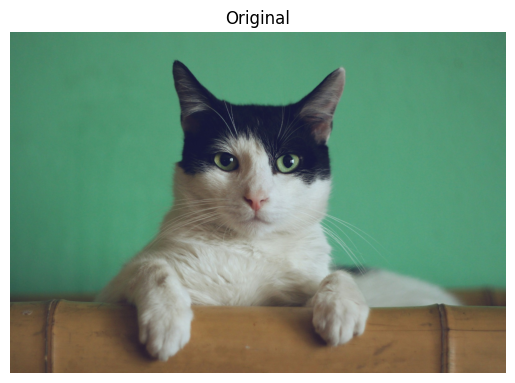

In [ ]:
img = Image.open(image_path).convert("RGB")
plt.imshow(img); plt.axis("off"); plt.title("Original"); plt.show()

## Step 5 — Reshape for batch processing

Not needed in PyTorch: each transform call takes the single image and returns one augmented version.

## Step 6 — Generate and save augmented images

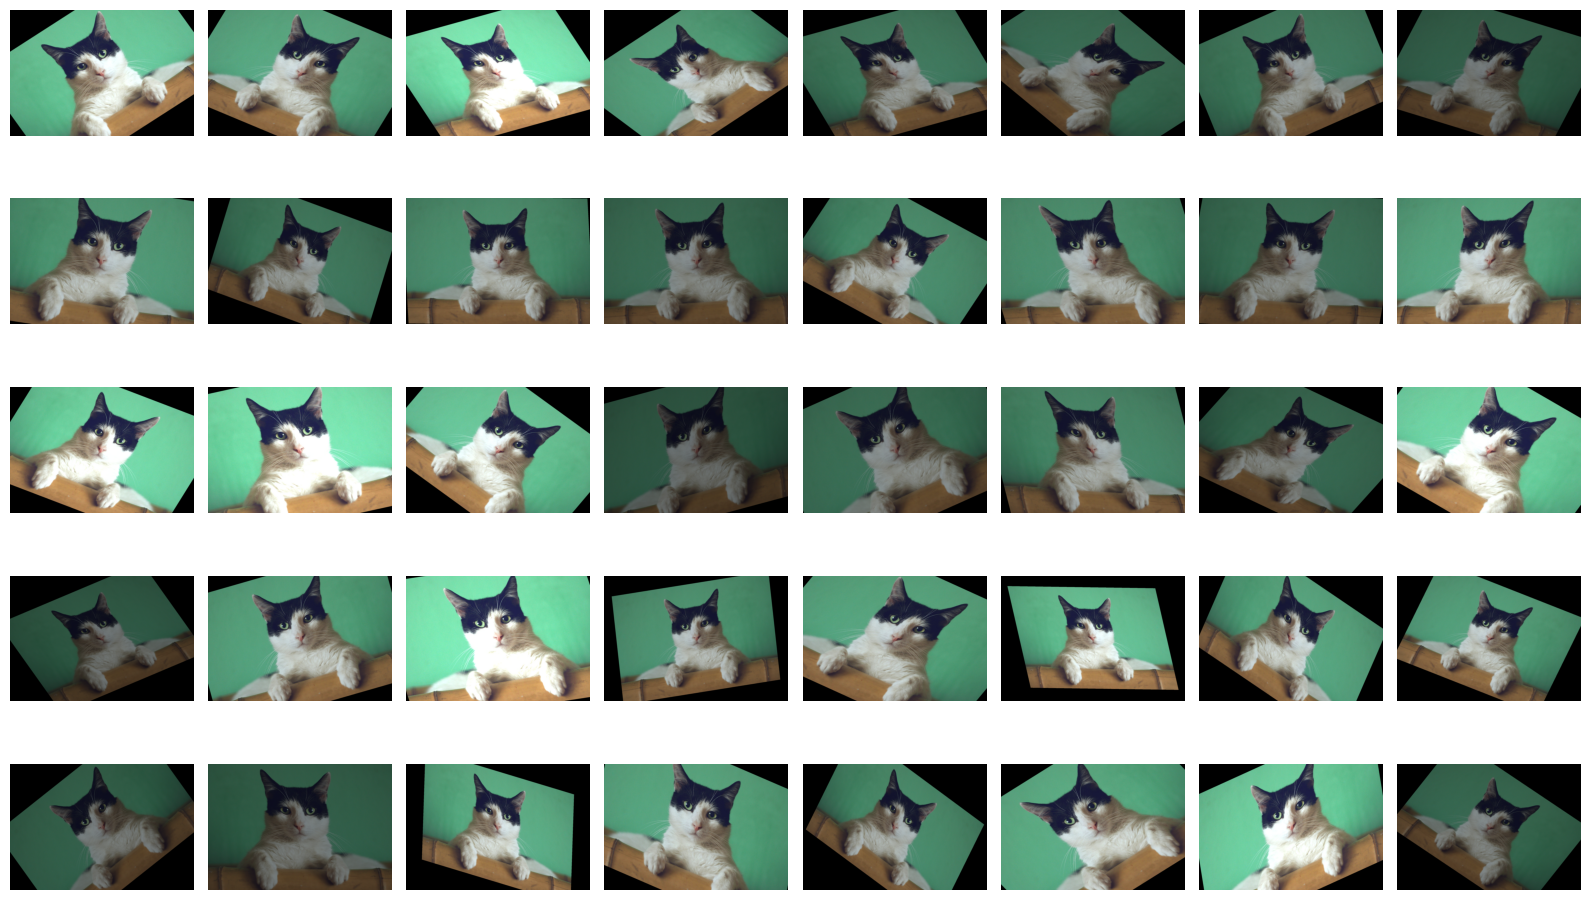

In [ ]:
saved_images = []
for i in range(num_images):
    augmented = augment(img)                                   # random augmented PIL image
    augmented.save(os.path.join(save_folder, f"image_{i+1:03d}.jpeg"), format="JPEG")
    saved_images.append(augmented)

# Show all augmented images in one grid
cols = 8
rows = (len(saved_images) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(2 * cols, 2 * rows))
for ax in axes.flat:
    ax.axis("off")
for ax, im in zip(axes.flat, saved_images):
    ax.imshow(im)
plt.tight_layout()
plt.show()

## Step 7 — Confirm the saved location

In [ ]:
print(f"Augmented images are saved in the folder: {os.path.abspath(save_folder)}")
print(f"Total images saved: {len(saved_images)}")

Augmented images are saved in the folder: /content/augmented
Total images saved: 40
